# Set 12 - AR, MA und ARMA: eine einfache Sinuswelle vorhersagen

Wir verwenden **eine glatte Sinuswelle mit sehr kleinem Messrauschen**. So erkennt man im Bild, welches Modell die Welle fortsetzen kann. Alle Fits verwenden ausschließlich `statsmodels.tsa.arima.model.ARIMA`.

Zuerst die Begriffe und die Wirkung eines einzelnen Schocks, danach der Vergleich auf denselben 72 zukünftigen Stunden. Die Prognosen entstehen **alle am selben Ursprung**: Kein tatsächlicher zukünftiger Messwert wird nachgereicht.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

kandidaten = [Path.cwd(), *Path.cwd().parents]
set_ordner = next((p for basis in kandidaten
                   for p in (basis, basis / "set12-zeitreihenanalyse")
                   if (p / "zeitreihen_tools.py").exists()), None)
if set_ordner is None:
    raise FileNotFoundError("Notebook bitte innerhalb des Kursordners starten.")
if str(set_ordner) not in sys.path:
    sys.path.insert(0, str(set_ordner))
from zeitreihen_tools import FARBEN, plot_stil, zeitachse, lag_tabelle
plot_stil()
from zeitreihen_demos import (demo_reihen, tagesmerkmale, arima_fit, feste_prognose,
    rollende_prognose, baselines, auswertung, zeitraum_plan, MODELL_SPECS)
from statsmodels.tsa.arima.model import ARIMA
from zeitreihen_demos import lesbare_tabelle


## 1. Drei Mechanismen statt drei Namen für dieselbe Sache

Für Reihen mit Mittelwert 0 und unabhängigen Zufallsschocks ε[t]:

| Modell | Beispielgleichung | Welche Vergangenheit wirkt? | statsmodels-Order |
|---|---|---|---|
| AR(1): autoregressiv | y[t] = 0.65 y[t−1] + ε[t] | letzter **Messwert** | (1, 0, 0) |
| MA(1): Moving Average | y[t] = ε[t] + 0.70 ε[t−1] | letzter **Zufallsschock** | (0, 0, 1) |
| ARMA(1,1) | y[t] = 0.60 y[t−1] + ε[t] + 0.60 ε[t−1] | Messwert und Zufallsschock | (1, 0, 1) |

Ein Zufallsschock ist der neue, vorher nicht vorhersagbare Anteil. Beim Fit sind diese Schocks unbekannt und werden aus der Reihe erschlossen. Nur in der Simulation kennen wir sie. **MA ist keine Glättung mittels rolling().mean()!**

AR(p) hat p vergangene Messwerte; MA(q) hat q vergangene Schocks. ARMA(p,q) kombiniert beides. d=0 bedeutet: keine Differenzierung. ARIMA in 04 vergleicht d=0 und d=1.

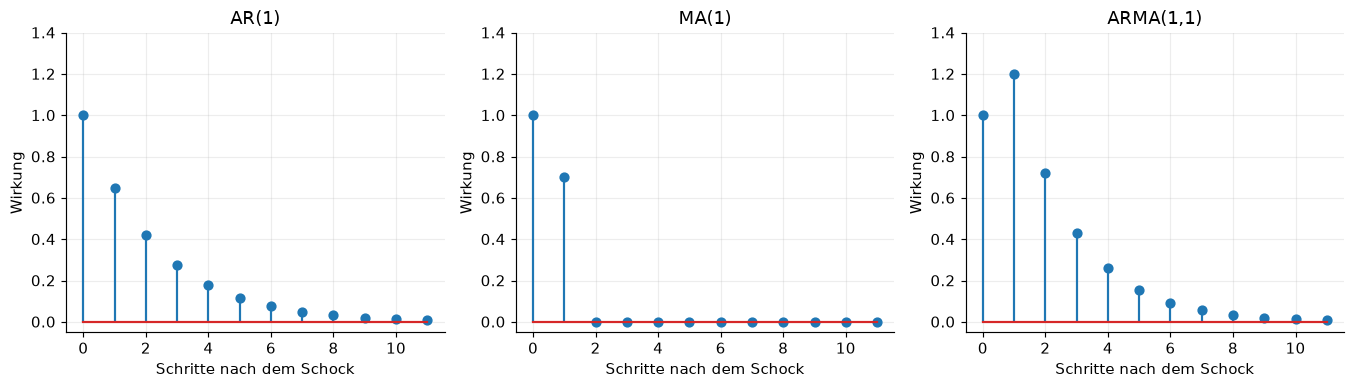

In [2]:
mechanismen = {"AR(1)": (0.65, 0.0), "MA(1)": (0.0, 0.70), "ARMA(1,1)": (0.60, 0.60)}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, (phi, theta)) in zip(axes, mechanismen.items()):
    shock = np.zeros(12); shock[0] = 1
    response = np.zeros(12); response[0] = 1
    for t in range(1, 12):
        response[t] = phi * response[t-1] + shock[t] + theta * shock[t-1]
    ax.stem(range(12), response)
    ax.set(title=name, xlabel="Schritte nach dem Schock", ylabel="Wirkung", ylim=(-0.05, 1.4))
plt.tight_layout(); plt.show()


## 2. Der leicht erkennbare Datensatz

`y[t] = 50 + 8 sin(2πt/24) + kleines Messrauschen`.

Die Periode beträgt 24 Stunden. Wir verwenden 240 Stunden Training, 48 Stunden Validierung und 72 Stunden Test. Der Seed ist 42, die Rauschstandardabweichung 0.03. Die Daten sind ausdrücklich synthetisch.

Für diesen festen Modellvergleich verwenden wir die ersten 288 Stunden als bekannte Historie. Die Orders stehen vorher fest. Die Validierung wird in den folgenden Notebooks zur Modellwahl eingesetzt.

,Daten,Abschnitt,Von,Bis,Stunden
0,Sinus,Training,2024-01-01,2024-01-10 23:00:00,240
1,Sinus,Validierung,2024-01-11,2024-01-12 23:00:00,48
2,Sinus,Test,2024-01-13,2024-01-15 23:00:00,72


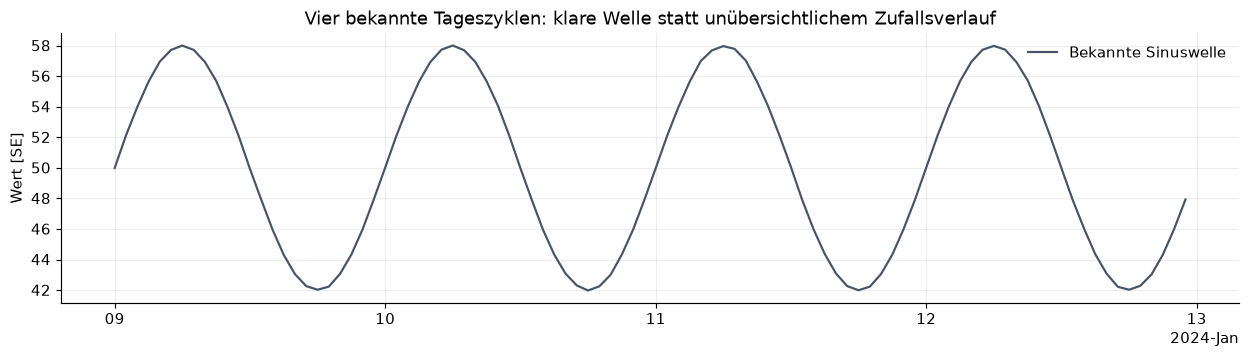

In [3]:
y = demo_reihen()["Sinus"]
historie, test = y.iloc[:288], y.iloc[288:]
display(zeitraum_plan({"Sinus": y}))
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(historie.iloc[-96:], color=FARBEN["roh"], label="Bekannte Sinuswelle")
ax.set(title="Vier bekannte Tageszyklen: klare Welle statt unübersichtlichem Zufallsverlauf", ylabel="Wert [SE]")
zeitachse(ax); ax.legend(); plt.tight_layout(); plt.show()


## 3. AR, MA und ARMA werden alle mit ARIMA gefittet

| Name im Vergleich | Aufruf / Order | Erwartung bei einer Sinuswelle |
|---|---|---|
| AR(1) | ARIMA(..., order=(1,0,0)) | Nur ein Lag reicht nicht für eine Schwingung |
| AR(2) | ARIMA(..., order=(2,0,0)) | Zwei Lags können eine Schwingung fortsetzen |
| MA(2) | ARIMA(..., order=(0,0,2)) | Erinnerung an Schocks endet nach zwei Schritten |
| ARMA(2,1) | ARIMA(..., order=(2,0,1)) | AR-Schwingung plus MA-Fehlerstruktur |

Für eine reine Sinuswelle gilt nach Abzug des Niveaus: `x[t] = 2 cos(2π/24) x[t−1] − x[t−2]`. Deshalb sind **zwei** AR-Lags sinnvoll. Die Schwingung liegt am Rand stationärer AR-Modelle; für diesen bewusst nahezu rauschfreien Lehrdatensatz erlauben wir mit `enforce_stationarity=False` diesen Grenzbereich.

Das MA-Modell soll hier sichtbar schlechter sein: So wird klar, wann die Modellfamilien passen. Die Vortags-Baseline ist bei einem unveränderten Tagesmuster bereits sehr stark.

In [4]:
fits = {}
# Der konkrete AR-Fit: auch hier ausschließlich die ARIMA-Funktion.
fits["AR(2)"] = ARIMA(historie, order=(2,0,0), trend="c", enforce_stationarity=False).fit(method_kwargs={"maxiter":1000})
if not fits["AR(2)"].mle_retvals["converged"]:
    raise RuntimeError("AR(2)-Fit nicht konvergiert.")
for name in ["AR(1)", "MA(2)", "ARMA(2,1)"]:
    order, _ = MODELL_SPECS[name]
    fits[name] = arima_fit(historie, order)
predictions = baselines(historie, test)
for name, fit in fits.items():
    predictions[name] = feste_prognose(fit, test.index).predicted_mean
vergleich = auswertung(test, predictions, "Sinus", "Fester Ursprung / 72 h")
display(lesbare_tabelle(vergleich.sort_values("MAE")))
print("Positive Prozentwerte: besser als die jeweilige Baseline. Negative: schlechter.")


Daten,Protokoll,Modell,MAE,RMSE,vs. letzter Wert [%],vs. Vortag [%],Besser als beide
Sinus,Fester Ursprung / 72 h,"ARMA(2,1)",0.0318,0.0372,+99.4%,+1.5%,ja
Sinus,Fester Ursprung / 72 h,Vortag (24 h),0.0323,0.0418,+99.4%,+0.0%,nein
Sinus,Fester Ursprung / 72 h,AR(2),0.0948,0.1132,+98.2%,-193.8%,nein
Sinus,Fester Ursprung / 72 h,MA(2),5.0800,5.6564,+3.0%,-15647.3%,nein
Sinus,Fester Ursprung / 72 h,Letzter Wert,5.2381,6.0217,+0.0%,-16137.4%,nein
Sinus,Fester Ursprung / 72 h,AR(1),5.2767,5.8586,-0.7%,-16257.0%,nein


Positive Prozentwerte: besser als die jeweilige Baseline. Negative: schlechter.


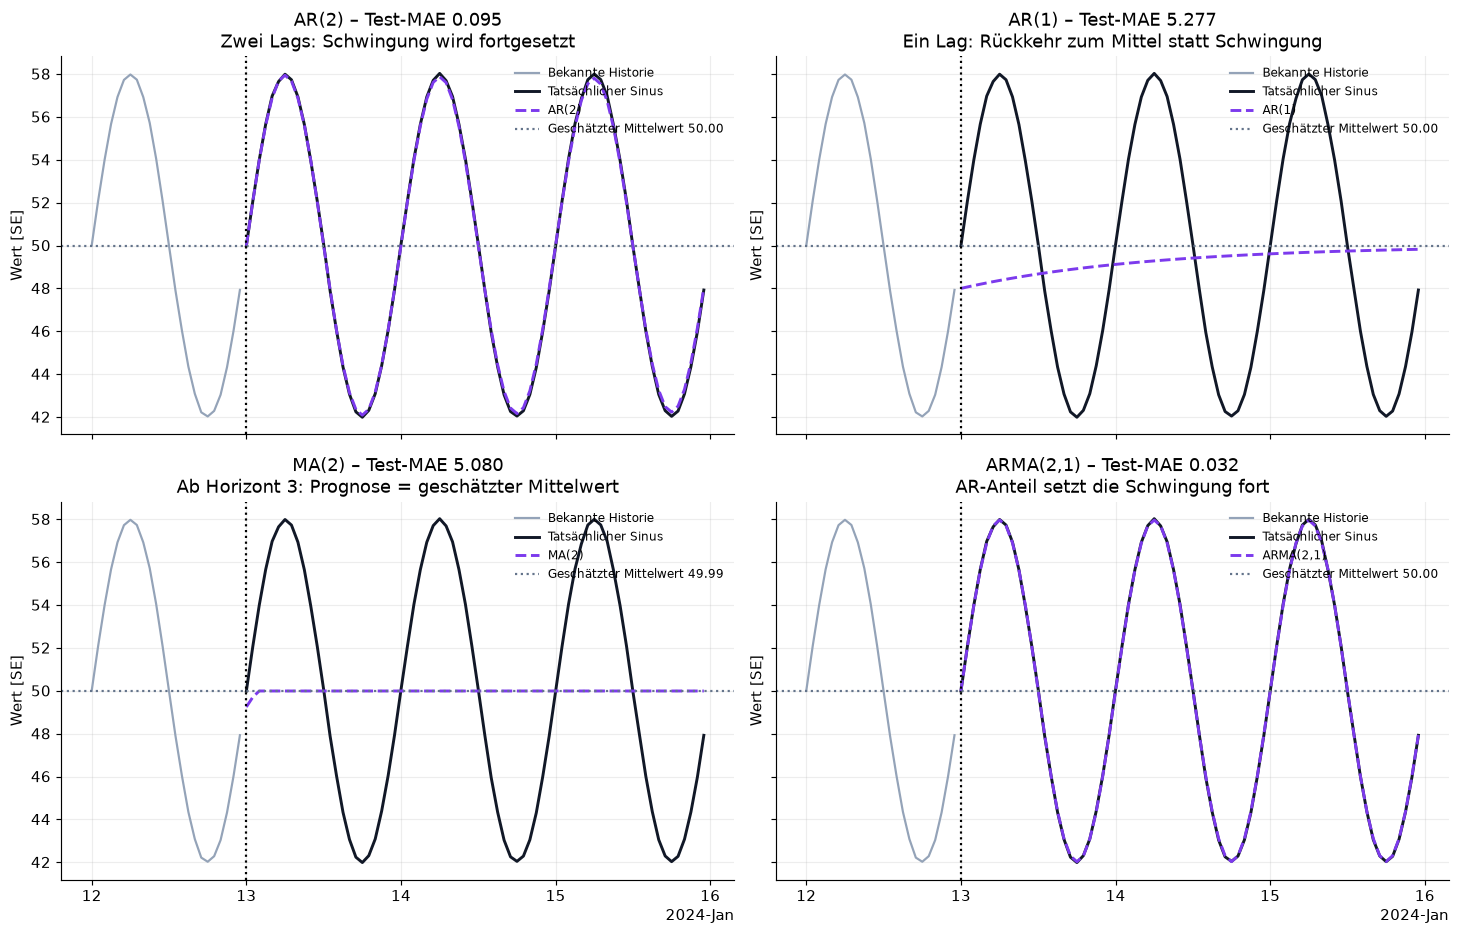

In [5]:
befunde = {
    "AR(1)": "Ein Lag: Rückkehr zum Mittel statt Schwingung",
    "AR(2)": "Zwei Lags: Schwingung wird fortgesetzt",
    "MA(2)": "Ab Horizont 3: Prognose = geschätzter Mittelwert",
    "ARMA(2,1)": "AR-Anteil setzt die Schwingung fort",
}
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), fits):
    ax.plot(historie.iloc[-24:], color="#94a3b8", label="Bekannte Historie")
    ax.plot(test, color="#111827", lw=2, label="Tatsächlicher Sinus")
    ax.plot(predictions[name], color=FARBEN["prognose"], lw=2, ls="--", label=name)
    mittel = float(fits[name].params["const"])
    ax.axhline(mittel, color="#64748b", ls=":", label=f"Geschätzter Mittelwert {mittel:.2f}")
    ax.axvline(test.index[0], color="black", ls=":")
    score = vergleich.set_index("Modell").loc[name, "MAE"]
    ax.set(title=f"{name} – Test-MAE {score:.3f}\n{befunde[name]}", ylabel="Wert [SE]")
    zeitachse(ax); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

## Das Ergebnis lesen

**AR(1) und MA(2) werden erfolgreich gefittet; ihre schwache 72-Stunden-Prognose ist hier erwartbar.** Eine erfolgreiche Schätzung bedeutet noch nicht, dass die Modellstruktur zu diesem Signal passt.

- **AR(1):** Für den zentrierten Wert gilt bei der Mehrschrittprognose näherungsweise `Prognose[h] = Mittelwert + phi**h * (letzter Wert − Mittelwert)`. Mit einem einzigen reellen AR-Koeffizienten kann das Modell die glatte 24-Stunden-Schwingung nicht fortsetzen. Für |phi| < 1 nähert es sich dem Mittelwert.
- **AR(2) und ARMA(2,1):** Zwei AR-Lags können diese Schwingung beschreiben. Die gestrichelte Prognose liegt deshalb fast auf der tatsächlichen Welle.
- **MA(2):** Nur die letzten zwei geschätzten Schocks wirken nach. Ab Horizont 3 sind alle relevanten Schocks zukünftig und haben Erwartungswert null; die Prognose ist der geschätzte Mittelwert. Eine flache Linie ist hier korrekt.
- Das gilt für diesen **festen 72-Stunden-Ursprung**. Bei rollenden Ein-Schritt-Prognosen kommen neue Messwerte hinzu; das ist eine andere Aufgabe.
- AR(1) kann für einen AR(1)-Prozess und MA(2) für einen MA(2)-Prozess gut geeignet sein. Der Sinusvergleich ist kein allgemeines Urteil über diese Modelle.
- Die Vortags-Baseline ist bei einem unveränderten Tagesmuster sehr stark; ihre Werte stehen in der Tabelle.

**Aufgaben:** Warum braucht die Sinuswelle zwei AR-Lags? Warum wird MA(2) ab Horizont 3 konstant? Warum bedeutet MA keine gleitende Mittelwertglättung?

Weiter mit 04: **Sinus plus Trend**, Vergleich ohne und mit Differenzierung und bekannte Tagesmerkmale.

Quelle: [statsmodels ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html).